In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Project root
PROJECT_ROOT = Path.cwd().parent

# Processed results directory
RESULTS_DIR = PROJECT_ROOT / "data" / "processed"

print(f"Project root: {PROJECT_ROOT}")
print(f"Results directory: {RESULTS_DIR}")

Project root: /home/Tam-Davies/Projects/ml-course-recommender
Results directory: /home/Tam-Davies/Projects/ml-course-recommender/data/processed


In [2]:
regression_results = pd.read_csv(
    RESULTS_DIR / "embedding_regression_results.csv"
)

classification_results = pd.read_csv(
    RESULTS_DIR / "embedding_classification_results.csv"
)

print("Regression results:")
display(regression_results)

print("\nClassification results:")
display(classification_results)

Regression results:


,Model,RMSE,MAE
0,LinearRegression,0.139921,0.062015
1,Ridge,0.139924,0.062006
2,Lasso,0.210945,0.089414
3,ElasticNet,0.210945,0.089414



Classification results:


,Model,Accuracy,Precision,Recall,F1,AUC
0,LogisticRegression,0.993635,0.994871,0.998471,0.996668,0.986744
1,RandomForest,0.994685,0.995364,0.999078,0.997218,0.991852


In [3]:
result_files = sorted(RESULTS_DIR.glob("*"))

print("Files currently in data/processed:")
for file in result_files:
    print(f"- {file.name}")

Files currently in data/processed:
- courses_bows.csv
- embedding_classification_results.csv
- embedding_regression_results.csv
- sim.csv


In [4]:
# Collaborative filtering model comparison

collaborative_results = pd.DataFrame({
    "Model": [
        "Item-Based KNN",
        "NMF",
        "Neural Network"
    ],
    "RMSE": [
        0.1945,
        0.2075,
        0.4076
    ]
})

collaborative_results = collaborative_results.sort_values(
    "RMSE"
).reset_index(drop=True)

display(collaborative_results)

,Model,RMSE
0,Item-Based KNN,0.1945
1,NMF,0.2075
2,Neural Network,0.4076


In [5]:
collaborative_results.to_csv(
    RESULTS_DIR / "collaborative_filtering_results.csv",
    index=False
)

print("Saved:")
print(RESULTS_DIR / "collaborative_filtering_results.csv")

Saved:
/home/Tam-Davies/Projects/ml-course-recommender/data/processed/collaborative_filtering_results.csv


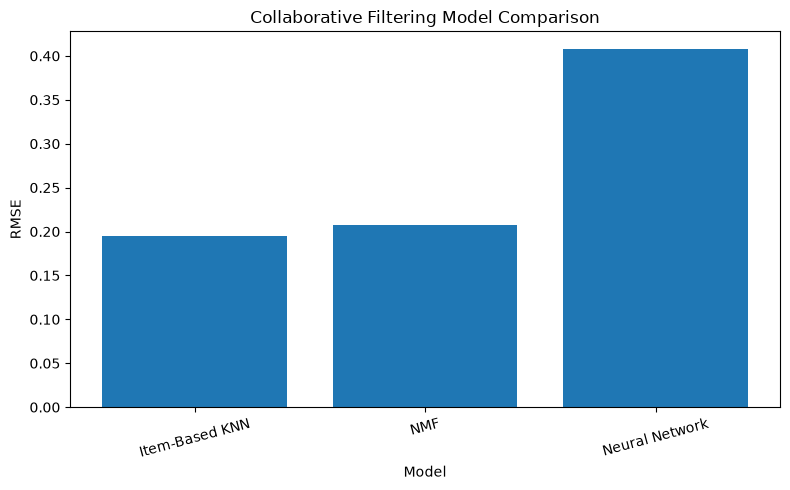

In [6]:
plt.figure(figsize=(8, 5))

plt.bar(
    collaborative_results["Model"],
    collaborative_results["RMSE"]
)

plt.ylabel("RMSE")
plt.xlabel("Model")
plt.title("Collaborative Filtering Model Comparison")
plt.xticks(rotation=15)
plt.tight_layout()

plt.show()

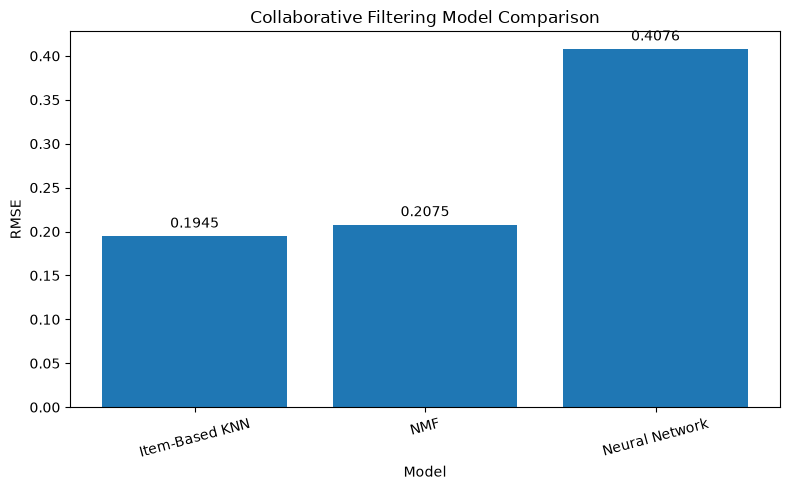

In [7]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    collaborative_results["Model"],
    collaborative_results["RMSE"]
)

plt.ylabel("RMSE")
plt.xlabel("Model")
plt.title("Collaborative Filtering Model Comparison")
plt.xticks(rotation=15)

for bar, value in zip(bars, collaborative_results["RMSE"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{value:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [8]:
display(
    regression_results.sort_values("RMSE").reset_index(drop=True)
)

,Model,RMSE,MAE
0,LinearRegression,0.139921,0.062015
1,Ridge,0.139924,0.062006
2,Lasso,0.210945,0.089414
3,ElasticNet,0.210945,0.089414


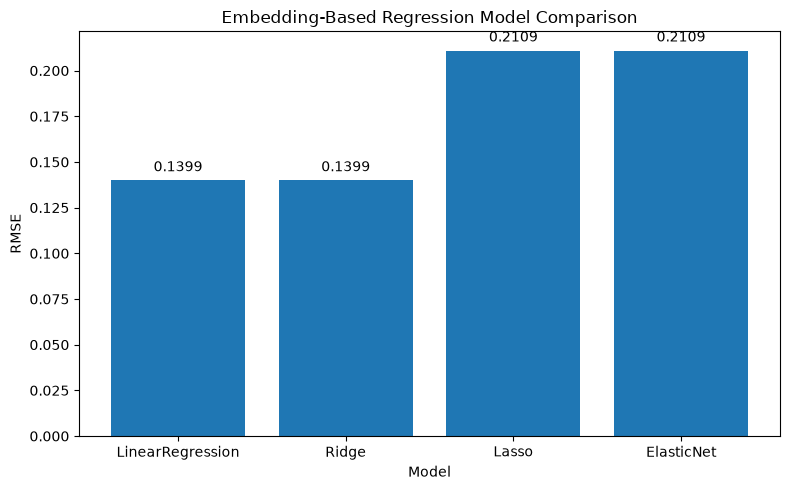

In [9]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    regression_results["Model"],
    regression_results["RMSE"]
)

plt.ylabel("RMSE")
plt.xlabel("Model")
plt.title("Embedding-Based Regression Model Comparison")

for bar, value in zip(bars, regression_results["RMSE"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f"{value:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [10]:
display(
    classification_results.sort_values("F1", ascending=False).reset_index(drop=True)
)

,Model,Accuracy,Precision,Recall,F1,AUC
0,RandomForest,0.994685,0.995364,0.999078,0.997218,0.991852
1,LogisticRegression,0.993635,0.994871,0.998471,0.996668,0.986744


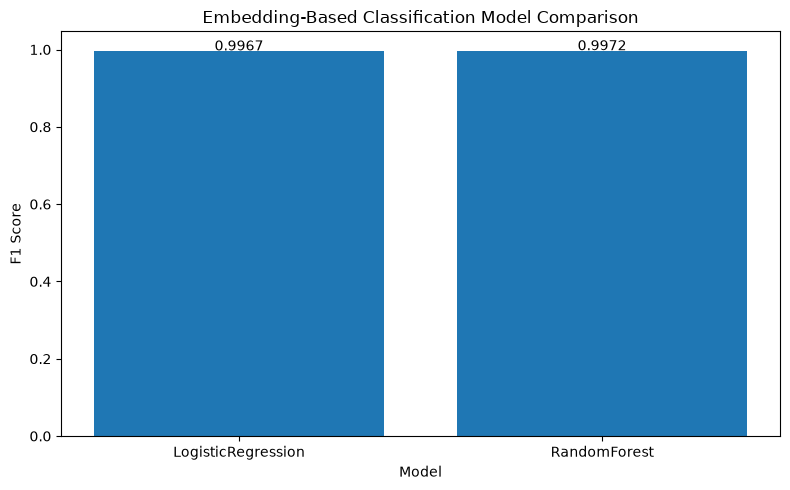

In [11]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    classification_results["Model"],
    classification_results["F1"]
)

plt.ylabel("F1 Score")
plt.xlabel("Model")
plt.title("Embedding-Based Classification Model Comparison")

for bar, value in zip(bars, classification_results["F1"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.001,
        f"{value:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.show()